# Assignment 3: Bank Customer Churn Prediction (Neural Network)
Dataset: [Churn Modelling Dataset (Kaggle)](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling)

Steps: read dataset -> feature/target split -> normalize -> build & train model -> accuracy score and confusion matrix.

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tf.random.set_seed(42)

## Step 1: Read the dataset

In [2]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.info()
df["Exited"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


Exited
0    7963
1    2037
Name: count, dtype: int64

## Step 2: Feature/target split, train/test split

In [4]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True)

X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train.shape, X_test.shape

((8000, 11), (2000, 11))

## Step 3: Normalize the train and test data

In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Step 4: Initialize and build the model

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1, verbose=2)

Epoch 1/20


225/225 - 0s - 2ms/step - accuracy: 0.7058 - loss: 0.5833 - val_accuracy: 0.8200 - val_loss: 0.4486


Epoch 2/20


225/225 - 0s - 668us/step - accuracy: 0.8097 - loss: 0.4506 - val_accuracy: 0.8425 - val_loss: 0.4024


Epoch 3/20


225/225 - 0s - 411us/step - accuracy: 0.8215 - loss: 0.4203 - val_accuracy: 0.8425 - val_loss: 0.3874


... (30 outputs left out)

Epoch 19/20


225/225 - 0s - 398us/step - accuracy: 0.8612 - loss: 0.3353 - val_accuracy: 0.8813 - val_loss: 0.3182


Epoch 20/20


225/225 - 0s - 401us/step - accuracy: 0.8615 - loss: 0.3345 - val_accuracy: 0.8800 - val_loss: 0.3180


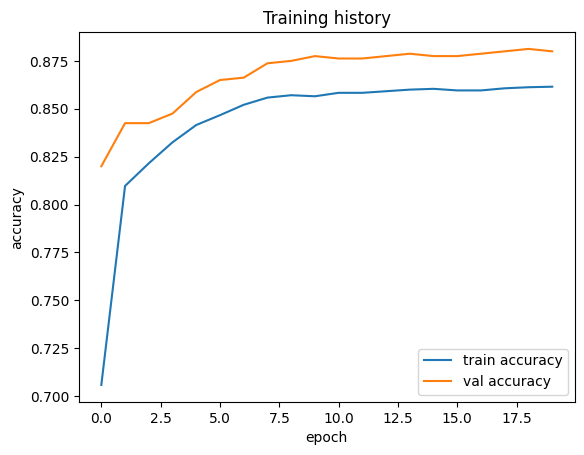

In [8]:
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.title("Training history")
plt.show()

## Step 5: Accuracy score and confusion matrix

 1/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 898us/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


Accuracy score: 0.8590


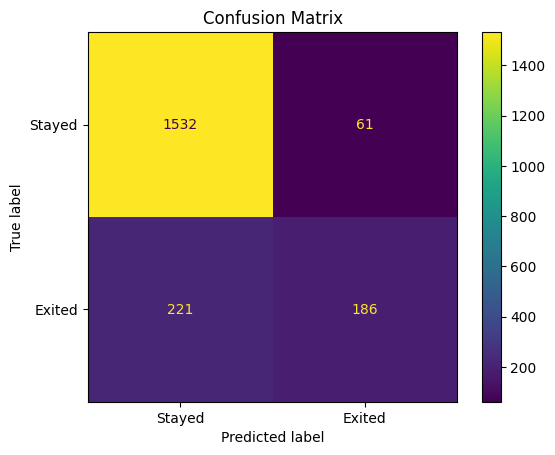

In [9]:
y_pred = (model.predict(X_test) > 0.5).astype(int).ravel()

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy score: {acc:.4f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stayed", "Exited"]).plot()
plt.title("Confusion Matrix")
plt.show()